In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from scipy.sparse import hstack, csr_matrix

from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold, learning_curve
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.preprocessing import label_binarize, StandardScaler, MinMaxScaler
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier, VotingClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report,
    roc_curve, auc, precision_recall_curve
)


[notice] A new release of pip is available: 26.0.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [ ]:
combined_df = pd.read_csv('combined_data.csv')
combined_df.head()

Class distribution of the processed DataFrame (df):
Sentiment
positive    9111
negative    9089
neutral     7580
Name: count, dtype: int64


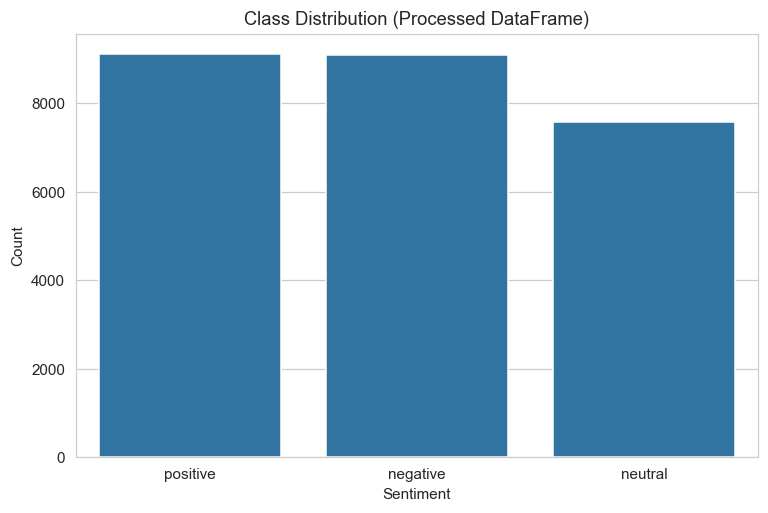

In [ ]:
df = combined_df.copy()

# Select only 'Comments' and 'Sentiment' columns
df = df[['Comments', 'Sentiment']]

# Basic sanity checks
assert {"Comments", "Sentiment"}.issubset(df.columns), "CSV must contain 'Comments' and 'Sentiment' columns"

# Drop rows where 'Comments' or 'Sentiment' are missing and reset index
df = df.dropna(subset=["Comments", "Sentiment"]).reset_index(drop=True)

# Convert 'Comments' to string type
df["Comments"] = df["Comments"].astype(str)

# Normalize sentiment labels to lowercase for consistency
df["Sentiment"] = df["Sentiment"].str.lower()

print("Class distribution of the processed DataFrame (df):")
print(df["Sentiment"].value_counts())

plt.figure(figsize=(8, 5))
sns.countplot(x="Sentiment", data=df, order=df["Sentiment"].value_counts().index)
plt.title("Class Distribution (Processed DataFrame)")
plt.xlabel("Sentiment")
plt.ylabel("Count")
plt.show()

In [ ]:
def clean_text(text: str) -> str:
    """Full Bangla-aware cleaning pipeline for one comment."""
    text = normalize_bangla(text)
    text = EMOJI_PATTERN.sub(" ", text)                       # remove emojis
    text = re.sub(r"http\S+|www\.\S+", " ", text)             # remove URLs
    text = re.sub(r"[0-9০-৯]+", " ", text)                    # remove Arabic + Bangla digits
    text = re.sub(r"[^ঀ-৿\s]", " ", text)              # keep only Bangla script + whitespace
    text = re.sub(r"\s+", " ", text).strip()
    return text

def tokenize(text: str):
    return text.split()

def remove_stopwords(tokens):
    return [t for t in tokens if t not in BANGLA_STOPWORDS]

def preprocess_pipeline(text: str) -> str:
    """Clean -> tokenize -> remove stopwords -> rejoin. Stemming/lemmatization for Bangla
    has no mature, universally-adopted library at the time of writing; this is left as a
    documented no-op hook so you can plug one in (e.g., BNLP, BLP) if available in your env."""
    cleaned = clean_text(text)
    tokens = tokenize(cleaned)
    tokens = remove_stopwords(tokens)
    # --- optional stemming/lemmatization hook ---
    # from bnlp import BasicTokenizer  # example; install if you want to use it
    # tokens = [stem(t) for t in tokens]
    return " ".join(tokens)

df["clean_comment"] = df["Comments"].apply(preprocess_pipeline)
df[["Comments", "clean_comment"]].head(10)


,Comments,clean_comment
0,জয় বাংলা কাপ! তাও আবার স্বাধীনতার মাস মার্চে। ...,জয় বাংলা কাপ তাও আবার স্বাধীনতার মাস মার্চে ম...
1,জয় বাংলা কাপ! তাও আবার স্বাধীনতার মাস মার্চে। ...,জয় বাংলা কাপ তাও আবার স্বাধীনতার মাস মার্চে ম...
2,বাংলাদেশের পরে ভারতের সাপর্ট ই করি ?,বাংলাদেশের ভারতের সাপর্ট ই করি
3,সৌম্যকে বাদ দেওয়া হোক,সৌম্যকে বাদ দেওয়া হোক
4,"প্রথমটি হচ্ছে, কোচ অত:পর সাকিব,সাকিব আর সাকিবর...",প্রথমটি হচ্ছে কোচ অত সাকিব সাকিব আর সাকিবরে দল...
5,"প্রথমটি হচ্ছে, কোচ অত:পর সাকিব,সাকিব আর সাকিবর...",প্রথমটি হচ্ছে কোচ অত সাকিব সাকিব আর সাকিবরে দল...
6,মুসফিক আর তামিমের বেটিং তান্ড়বে কুহিলির জিব্ব...,মুসফিক আর তামিমের বেটিং তান্ড়বে কুহিলির জিব্ব...
7,সত্যি সত্যিই ছিলো বাঘ আমাদেরই চাপে হয়ে গেলো ব...,সত্যি সত্যিই ছিলো বাঘ আমাদেরই চাপে হয়ে গেলো ব...
8,",বাংলাদেশ জিদবে ইনশা আল্লাহ",বাংলাদেশ জিদবে ইনশা আল্লাহ
9,"ক্রিকেটে ভারত একটা অসভ্য দল,বিরাট কোহলির আচরনে...",ক্রিকেটে ভারত একটা অসভ্য দল বিরাট কোহলির আচরনে...


In [ ]:
tfidf_char = TfidfVectorizer(
    analyzer="char_wb",
    ngram_range=(3, 5),
    max_features=3000,
    min_df=2
)

In [ ]:
X_text = df["clean_comment"].values
y_raw_str = df["Sentiment"].values


classes = sorted(pd.unique(y_raw_str))
n_classes = len(classes)
print("Original Classes:", classes)


label_encoder = LabelEncoder()
y_raw_encoded = label_encoder.fit_transform(y_raw_str)

X_train_text, X_test_text, y_train_encoded, y_test_encoded = train_test_split(
    X_text, y_raw_encoded, test_size=0.2, random_state=SEED, stratify=y_raw_encoded
)


y_train = label_encoder.inverse_transform(y_train_encoded)
y_test = label_encoder.inverse_transform(y_test_encoded)

print("Classes", classes)

Original Classes: ['negative', 'neutral', 'positive']
Classes ['negative', 'neutral', 'positive']


In [ ]:
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=SEED),
    "Naive Bayes": MultinomialNB(),
    "SVM": SVC(kernel="linear", probability=True, random_state=SEED),
    "Random Forest": RandomForestClassifier(n_estimators=300, random_state=SEED),
}

trained_models = {}
for name, model in models.items():
    model.fit(X_train, y_train)
    trained_models[name] = model
    print(f"Trained: {name}")

Trained: Logistic Regression
Trained: Naive Bayes
Trained: SVM
Trained: Random Forest


In [ ]:
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
for name, model in models.items():
    scores = cross_val_score(model, X_train, y_train, cv=skf, scoring="f1_macro")
    print(f"{name}: CV macro-F1 = {scores.mean():.4f} (+/- {scores.std():.4f})")

Logistic Regression: CV macro-F1 = 0.8360 (+/- 0.0048)
Naive Bayes: CV macro-F1 = 0.8179 (+/- 0.0035)
SVM: CV macro-F1 = 0.8347 (+/- 0.0043)
Random Forest: CV macro-F1 = 0.8361 (+/- 0.0045)


In [ ]:
ensemble = VotingClassifier(
    estimators=[(name, model) for name, model in trained_models.items()],
    voting="soft"
)
ensemble.fit(X_train, y_train)
trained_models["Ensemble (Soft Voting)"] = ensemble
print("Ensemble trained.")

Ensemble trained.


In [ ]:
results = []
predictions = {}
probabilities = {}

for name, model in trained_models.items():
    y_pred = model.predict(X_test)
    predictions[name] = y_pred
    if hasattr(model, "predict_proba"):
        probabilities[name] = model.predict_proba(X_test)

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision (macro)": precision_score(y_test, y_pred, average="macro", zero_division=0),
        "Precision (weighted)": precision_score(y_test, y_pred, average="weighted", zero_division=0),
        "Recall (macro)": recall_score(y_test, y_pred, average="macro", zero_division=0),
        "Recall (weighted)": recall_score(y_test, y_pred, average="weighted", zero_division=0),
        "F1 (macro)": f1_score(y_test, y_pred, average="macro", zero_division=0),
        "F1 (weighted)": f1_score(y_test, y_pred, average="weighted", zero_division=0),
    })

results_df = pd.DataFrame(results).sort_values("F1 (macro)", ascending=False)
results_df

,Model,Accuracy,Precision (macro),Precision (weighted),Recall (macro),Recall (weighted),F1 (macro),F1 (weighted)
4,Ensemble (Soft Voting),0.833398,0.846166,0.837682,0.840542,0.833398,0.841909,0.834023
3,Random Forest,0.829325,0.843212,0.834759,0.836595,0.829325,0.837672,0.829690
0,Logistic Regression,0.827192,0.838227,0.829420,0.834696,0.827192,0.836154,0.827991
2,SVM,0.826028,0.837432,0.828419,0.833558,0.826028,0.835217,0.826942
1,Naive Bayes,0.805081,0.823083,0.813669,0.812459,0.805081,0.814580,0.806030


In [ ]:
# Save the results DataFrame to Google Drive
results_output_path = os.path.join(DRIVE_OUTPUT_PATH, 'model_performance_results.csv')
results_df.to_csv(results_output_path, index=False)
print(f"Results DataFrame saved to: {results_output_path}")

Results DataFrame saved to: C:/Users/pciuc/OneDrive/Desktop/Mithila_CSE_30_A/Cricket/Results\model_performance_results.csv


In [ ]:
import os

reports_output_path = os.path.join(DRIVE_OUTPUT_PATH, 'all_classification_reports.txt')

with open(reports_output_path, 'w') as f:
    for name, y_pred in predictions.items():
        report_str = classification_report(y_test, y_pred, zero_division=0, digits=4)

        # Print to console
        print(f"\n===== {name} =====")
        print(report_str)

        # Write to file
        f.write(f"===== {name} =====\n")
        f.write(report_str)
        f.write("\n\n") # Add extra newlines for separation in the file

print(f"\nAll classification reports saved to: {reports_output_path}")


===== Logistic Regression =====
              precision    recall  f1-score   support

    negative     0.7475    0.7882    0.7673      1818
     neutral     0.9878    0.9617    0.9746      1516
    positive     0.7794    0.7541    0.7665      1822

    accuracy                         0.8272      5156
   macro avg     0.8382    0.8347    0.8362      5156
weighted avg     0.8294    0.8272    0.8280      5156


===== Naive Bayes =====
              precision    recall  f1-score   support

    negative     0.6958    0.8190    0.7524      1818
     neutral     0.9834    0.9367    0.9595      1516
    positive     0.7901    0.6817    0.7319      1822

    accuracy                         0.8051      5156
   macro avg     0.8231    0.8125    0.8146      5156
weighted avg     0.8137    0.8051    0.8060      5156


===== SVM =====
              precision    recall  f1-score   support

    negative     0.7467    0.7849    0.7654      1818
     neutral     0.9905    0.9611    0.9756      1516


Confusion matrices plot saved to: C:/Users/pciuc/OneDrive/Desktop/Mithila_CSE_30_A/Cricket/Results\confusion_matrices.png


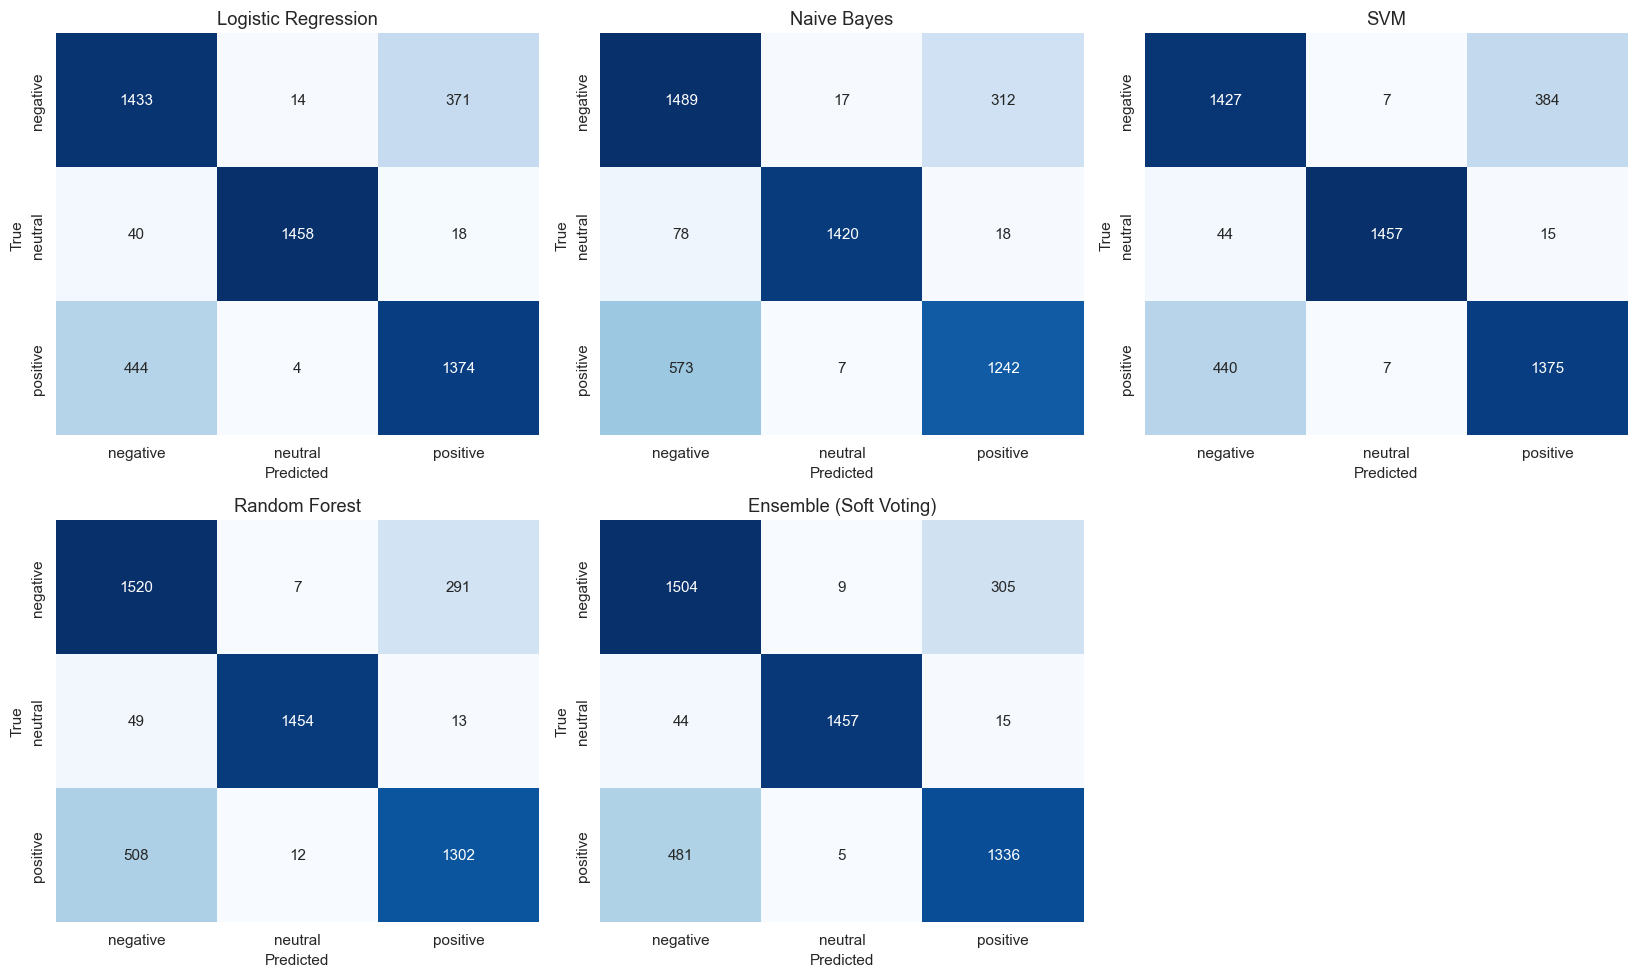

In [ ]:
n_models = len(trained_models)
n_cols = 3
n_rows = int(np.ceil(n_models / n_cols))

fig, axes = plt.subplots(n_rows, n_cols, figsize=(5 * n_cols, 4.5 * n_rows))
axes = np.array(axes).reshape(-1)

for ax, (name, y_pred) in zip(axes, predictions.items()):
    cm = confusion_matrix(y_test, y_pred, labels=classes)
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
                xticklabels=classes, yticklabels=classes, ax=ax, cbar=False)
    ax.set_title(name)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("True")

for ax in axes[len(predictions):]:
    ax.axis("off")

plt.tight_layout()

# Save the confusion matrices plot to Google Drive
plot_output_path = os.path.join(DRIVE_OUTPUT_PATH, 'confusion_matrices.png')
plt.savefig(plot_output_path)
print(f"Confusion matrices plot saved to: {plot_output_path}")

plt.show()

ROC curves plot saved to: C:/Users/pciuc/OneDrive/Desktop/Mithila_CSE_30_A/Cricket/Results\roc_curves.png


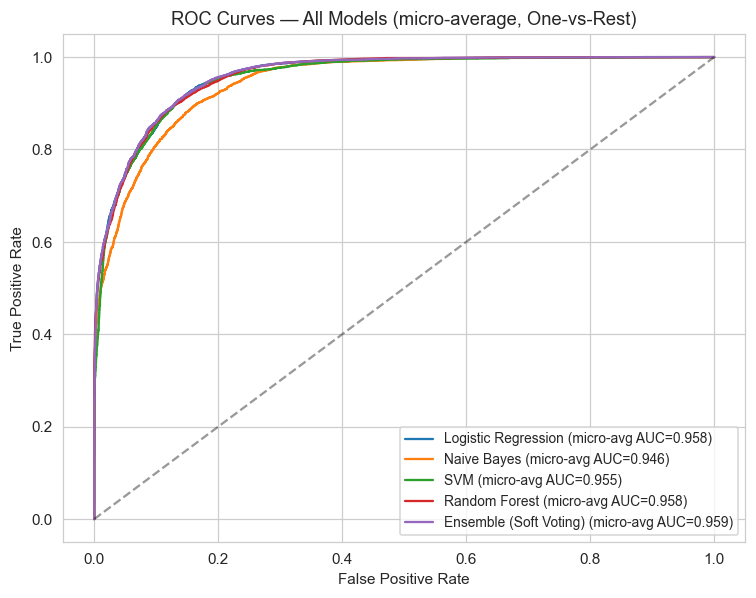

In [ ]:
y_test_bin = label_binarize(y_test, classes=classes)
is_binary = n_classes == 2

plt.figure(figsize=(8, 6))
for name, proba in probabilities.items():
    if is_binary:
        # label_binarize gives a single column for binary; use the positive-class probability
        fpr, tpr, _ = roc_curve(y_test_bin.ravel(), proba[:, 1])
        roc_auc = auc(fpr, tpr)
        plt.plot(fpr, tpr, label=f"{name} (AUC={roc_auc:.3f})")
    else:
        # micro-average ROC across all classes (One-vs-Rest)
        fpr, tpr, _ = roc_curve(y_test_bin.ravel(), proba.ravel())
        roc_auc = auc(fpr, tpr)
        plt.plot(fpr, tpr, label=f"{name} (micro-avg AUC={roc_auc:.3f})")

plt.plot([0, 1], [0, 1], "k--", alpha=0.4)
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curves — All Models" + ("" if is_binary else " (micro-average, One-vs-Rest)"))
plt.legend(loc="lower right", fontsize=9)

# Save the ROC curves plot to Google Drive
roc_plot_output_path = os.path.join(DRIVE_OUTPUT_PATH, 'roc_curves.png')
plt.savefig(roc_plot_output_path)
print(f"ROC curves plot saved to: {roc_plot_output_path}")

plt.show()

Per-Class ROC plot saved to: C:/Users/pciuc/OneDrive/Desktop/Mithila_CSE_30_A/Cricket/Results\per_class_roc_ensemble.png


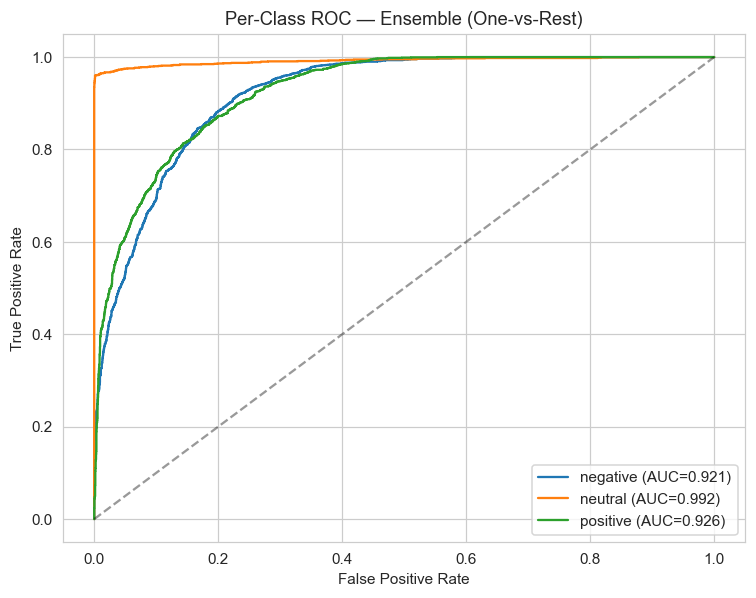

In [ ]:
if not is_binary and "Ensemble (Soft Voting)" in probabilities:
    proba = probabilities["Ensemble (Soft Voting)"]
    plt.figure(figsize=(8, 6))
    for i, cls in enumerate(classes):
        fpr, tpr, _ = roc_curve(y_test_bin[:, i], proba[:, i])
        roc_auc = auc(fpr, tpr)
        plt.plot(fpr, tpr, label=f"{cls} (AUC={roc_auc:.3f})")
    plt.plot([0, 1], [0, 1], "k--", alpha=0.4)
    plt.xlabel("False Positive Rate")
    plt.ylabel("True Positive Rate")
    plt.title("Per-Class ROC — Ensemble (One-vs-Rest)")
    plt.legend(loc="lower right")

    # Save the Per-Class ROC plot
    per_class_roc_path = os.path.join(DRIVE_OUTPUT_PATH, 'per_class_roc_ensemble.png')
    plt.savefig(per_class_roc_path)
    print(f"Per-Class ROC plot saved to: {per_class_roc_path}")

    plt.show()
else:
    print("Skipped: binary case already fully shown above.")
